# Kammler Synthetic — SDQT vs. k

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

import sys
sys.path.insert(0, "../..")
from src.tests.style import set_thesis_style, TEXT_WIDTH_IN, BLUE, ORANGE

set_thesis_style(use_tex=False)

RESULTS = Path("../../results")
CONDITIONS = ["gaussian", "baseline", "amplitude_mod"]
METHOD_COLORS = {"neurokit": BLUE, "i2dsw": ORANGE}
FILTER_STYLES = {"own": "-", "orini": (0, (4, 2))}
DURATION_S = 15.0  # kammler_synthetic_v2.csv also contains other segment
                    # lengths (full, 120s, ...); filter explicitly, do not
                    # rely on the filename

In [2]:
df = pd.read_csv(RESULTS / "kammler_synthetic_v2.csv")
df = df[(df.status == "ok") & (df.duration_cfg == DURATION_S)].copy()
df["k"] = df["k"].astype(float)
df = df.sort_values("k")
assert df.duplicated(subset=["k", "condition", "method", "filter_cfg"]).sum() == 0, \
    "more than one row per (k, condition, method, filter_cfg) -- filter is not selective enough"
df.head()

,k,condition,method,filter_cfg,duration_cfg,sdqt,sdrt,qtvi,n_beats,n_rejected,n_t_amp_nan,n_iso_fallback,n_failed,threshold_uv,n_kept,n_total,elapsed_s,status,error
0,0.1,gaussian,neurokit,orini,15.0,6.702468,4.704452,NaN,14,6,6,0,0,NaN,NaN,20,0.1,ok,NaN
1,0.1,baseline,neurokit,orini,15.0,2.762531,2.672964,NaN,20,0,0,0,0,NaN,NaN,20,0.1,ok,NaN
2,0.1,gaussian,neurokit,own,15.0,36.062801,5.334280,NaN,13,7,0,0,0,NaN,NaN,20,0.2,ok,NaN
3,0.1,baseline,neurokit,own,15.0,1.848897,1.559352,NaN,20,0,0,0,0,NaN,NaN,20,0.1,ok,NaN
4,0.1,amplitude_mod,neurokit,orini,15.0,3.181793,1.612452,NaN,15,5,5,0,0,NaN,NaN,20,0.1,ok,NaN


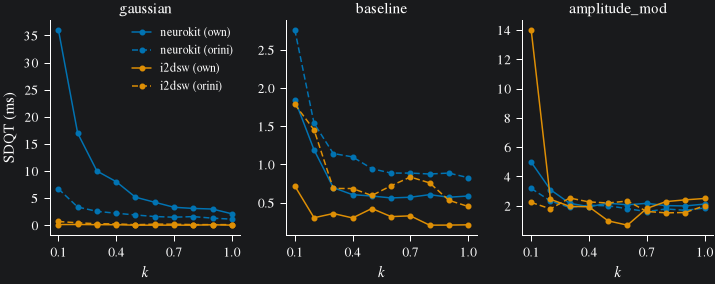

In [3]:
fig, axes = plt.subplots(1, len(CONDITIONS), figsize=(TEXT_WIDTH_IN, 2.6),
                         sharex=True)

for ax, cond in zip(axes, CONDITIONS):
    sub = df[df.condition == cond]
    for method, color in METHOD_COLORS.items():
        for filter_cfg, style in FILTER_STYLES.items():
            m = sub[(sub.method == method) & (sub.filter_cfg == filter_cfg)].sort_values("k")
            if m.empty:
                continue
            label = f"{method} ({filter_cfg})"
            ax.plot(m.k, m.sdqt, ls=style, marker="o", color=color, label=label,
                    ms=2.6, lw=0.9)
    ax.set_title(cond, pad=4)
    ax.set_xlabel("$k$")
    ax.set_xticks([0.1, 0.4, 0.7, 1.0])
    ax.tick_params(labelleft=True)

axes[0].set_ylabel("SDQT (ms)")
axes[0].legend(loc="upper right", fontsize=7, handlelength=1.6, borderaxespad=0.2)
fig.tight_layout()
plt.show()

In [4]:
df_15 = pd.read_csv(RESULTS / "kammler_synthetic_v2.csv")
df_15 = df_15[(df_15.status == "ok") & (df_15.duration_cfg == 15.0)].copy()

df_360 = pd.read_csv(RESULTS / "kammler_synthetic_360s_v2.csv")
df_360 = df_360[(df_360.status == "ok") & (df_360.duration_cfg == 360.0)].copy()

df_all = pd.concat([df_15, df_360], ignore_index=True)

i2dsw = df_all[df_all.method == "i2dsw"]
sdqt_means = i2dsw.groupby(["duration_cfg", "filter_cfg"])["sdqt"].mean()

print("i2DSW SDQT-Mittelwert (über alle Rauschtypen und k):")
for duration in (15.0, 360.0):
    for filter_cfg in ("own", "orini"):
        val = sdqt_means.loc[(duration, filter_cfg)]
        print(f"  {duration:.0f} Beats, filter={filter_cfg}: {val:.3f} ms")

neurokit = df_all[df_all.method == "neurokit"]
nk_sdqt_means = neurokit.groupby(["duration_cfg", "filter_cfg"])["sdqt"].mean()

print("\nNeurokit SDQT-Mittelwert (über alle Rauschtypen und k):")
for duration in (15.0, 360.0):
    for filter_cfg in ("own", "orini"):
        val = nk_sdqt_means.loc[(duration, filter_cfg)]
        print(f"  {duration:.0f} Beats, filter={filter_cfg}: {val:.3f} ms")

i2DSW SDQT-Mittelwert (über alle Rauschtypen und k):
  15 Beats, filter=own: 1.160 ms
  15 Beats, filter=orini: 1.027 ms
  360 Beats, filter=own: 1.182 ms
  360 Beats, filter=orini: 1.039 ms

Neurokit SDQT-Mittelwert (über alle Rauschtypen und k):
  15 Beats, filter=own: 4.146 ms
  15 Beats, filter=orini: 1.856 ms
  360 Beats, filter=own: 5.133 ms
  360 Beats, filter=orini: 2.500 ms
